# Escolha de distribuição discreta com sistema especialista e aprendizado supervisionado

- **Disciplina:** Inteligência Artificial e LFA | Sistemas Especialistas (UDF), Aula 13.

## Problema escolhido

Dada uma situação descrita em uma frase, recomendar qual distribuição discreta de probabilidade usar.

- **Público:** estudantes e analistas que precisam escolher a distribuição certa para uma situação.
- **Entrada do modelo:** a frase que descreve a situação (texto).
- **Rótulo previsto:** contagemintervalo, repetemeta ou nfixo.
- **Fatos da consulta** semreposicao, n1 e r1.
- **Recomendação:** uma entre Poisson, Geométrica, Pascal, Hipergeométrica, Bernoulli e Binomial.

Significado dos rótulos:
- **contagemintervalo:** conta ocorrências dentro de um intervalo de tempo, área ou volume.
- **repetemeta:** repete tentativas até atingir um número de sucessos.
- **nfixo:** o número de tentativas ou extrações é definido de antemão.

Significado dos fatos da consulta:
- **semreposicao:** as extrações são feitas sem reposição, de uma população finita.
- **n1:** o número fixo de tentativas é exatamente 1.
- **r1:** a meta de sucessos para parar é exatamente 1.

Divisão de papéis: o modelo aprende a identificar o tipo da situação a partir do texto, e as regras, escritas por humanos com base na teoria, transformam tipo e fatos em uma distribuição.

## Estudo inicial

- **O que é aprendizado de máquina:** área da IA em que um algoritmo aprende padrões a partir de dados, em vez de seguir apenas regras escritas à mão, e usa esses padrões para prever casos novos.
- **O que caracteriza o supervisionado:** o modelo treina com exemplos que já trazem a resposta correta (rótulo) e aprende a relação entre entradas e rótulos.
- **Atributos e rótulos:** atributos são as entradas do modelo (aqui, as palavras da frase) e o rótulo é a resposta conhecida que ele deve prever (aqui, o tipo da situação).
- **Classificação e regressão:** classificação prevê categorias (neste trabalho, 3 tipos) e regressão prevê valores numéricos (por exemplo, um preço).
- **Por que separar treino e teste:** o treino ensina o modelo e o teste, com exemplos que ele nunca viu, mostra se ele generaliza ou apenas decorou os exemplos.

## Base de conhecimento e origem das regras

Cada regra vem do critério teórico da distribuição:

- **R1:** SE tipo = contagemintervalo, ENTÃO Poisson. Origem: conta ocorrências em intervalo contínuo (tempo, área, volume) com taxa média constante.
- **R2:** SE tipo = repetemeta E r1, ENTÃO Geométrica. Origem: número de tentativas até o primeiro sucesso.
- **R3:** SE tipo = repetemeta E NÃO r1, ENTÃO Pascal. Origem: número de tentativas até o r-ésimo sucesso, com r maior que 1.
- **R4:** SE tipo = nfixo E semreposicao, ENTÃO Hipergeométrica. Origem: n extrações sem reposição de uma população finita, em que p muda a cada extração.
- **R5:** SE tipo = nfixo E NÃO semreposicao E n1, ENTÃO Bernoulli. Origem: uma única tentativa com dois resultados possíveis.
- **R6:** SE tipo = nfixo E NÃO semreposicao E NÃO n1, ENTÃO Binomial. Origem: n tentativas independentes com p constante, contando sucessos.

## Dataset

- **Registros:** 30 frases curtas, 10 por classe.
- **Origem:** dados simulados, escritos pelo próprio grupo apenas para demonstrar o procedimento.
- **Atributo:** frase (texto).
- **Rótulo:** tipo.
- **Critério de rotulagem:** contagemintervalo para frases que contam eventos em um intervalo, repetemeta para frases que repetem tentativas até uma meta de sucessos e nfixo para frases com número de tentativas definido de antemão.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Dados simulados, escritos para fins didáticos
contagem = [
    "quantas ligações chegam à central por hora",
    "número de clientes que entram na loja por dia",
    "defeitos encontrados por metro de tecido",
    "e-mails recebidos por minuto no servidor",
    "quantos carros passam no pedágio por hora",
    "falhas de rede registradas por mês",
    "erros de digitação por página de um livro",
    "chamadas de emergência recebidas a cada hora",
    "bactérias por mililitro de água",
    "pacientes que chegam ao pronto-socorro por noite",
]
repete = [
    "quantas tentativas até passar na prova de direção",
    "número de lançamentos até sair a primeira coroa",
    "quantas peças inspecionar até encontrar a quinta defeituosa",
    "quantas ligações fazer até fechar três vendas",
    "quantas vezes tentar até acertar o primeiro pênalti",
    "número de candidatos entrevistados até contratar dois",
    "quantos dias esperar até a primeira chuva",
    "quantos clientes abordar até conseguir a primeira venda",
    "quantas partidas jogar até vencer três",
    "quantos produtos testar até achar o segundo com defeito",
]
fixo = [
    "quantas caras saem em 10 lançamentos de moeda",
    "número de peças defeituosas em um lote de 20 inspecionadas",
    "quantos alunos acertam em uma prova de 15 questões",
    "a moeda sai cara em um único lançamento",
    "quantas bolas vermelhas saem ao retirar 5 de uma urna sem devolução",
    "número de cartas de copas ao sortear 5 de um baralho",
    "quantos eleitores apoiam o candidato em 50 entrevistados",
    "o paciente responde ao tratamento em uma aplicação",
    "quantos itens defeituosos em uma amostra de 8 retirados de uma caixa com 30",
    "o jogador acerta uma única cobrança de falta",
]

dados = pd.DataFrame({
    "frase": contagem + repete + fixo,
    "tipo": ["contagemintervalo"] * 10 + ["repetemeta"] * 10 + ["nfixo"] * 10,
})
dados.to_csv("datasetdistribuicoes.csv", index=False, encoding="utf-8")
print(dados.to_string(index=False))
print("\nQuantidade por classe:")
print(dados["tipo"].value_counts())

                                                                      frase              tipo
                                 quantas ligações chegam à central por hora contagemintervalo
                              número de clientes que entram na loja por dia contagemintervalo
                                   defeitos encontrados por metro de tecido contagemintervalo
                                   e-mails recebidos por minuto no servidor contagemintervalo
                                  quantos carros passam no pedágio por hora contagemintervalo
                                         falhas de rede registradas por mês contagemintervalo
                                  erros de digitação por página de um livro contagemintervalo
                               chamadas de emergência recebidas a cada hora contagemintervalo
                                            bactérias por mililitro de água contagemintervalo
                           pacientes que chegam ao pronto-so

## Separação em treino e teste e treinamento

O CountVectorizer transforma o texto em contagem de palavras, que são os atributos numéricos. O DecisionTreeClassifier aprende as condições a partir dessas contagens.

Treino: 22 | Teste: 8
Acurácia no teste: 87.5%
                   contagemintervalo  repetemeta  nfixo
contagemintervalo                  1           0      1
repetemeta                         0           3      0
nfixo                              0           0      3


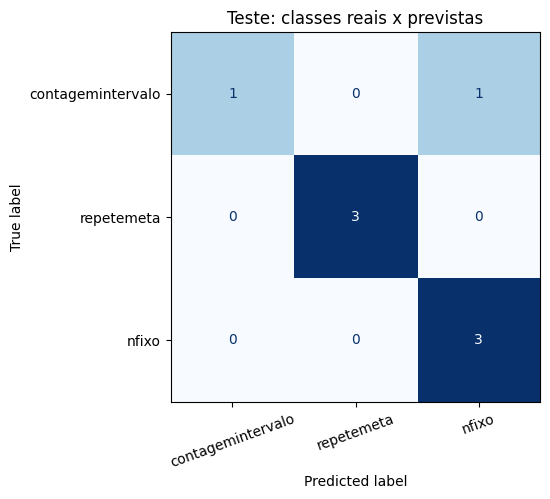

Condições aprendidas (palavras usadas pela árvore):
|--- por <= 0.50
|   |--- até <= 0.50
|   |   |--- class: nfixo
|   |--- até >  0.50
|   |   |--- class: repetemeta
|--- por >  0.50
|   |--- class: contagemintervalo



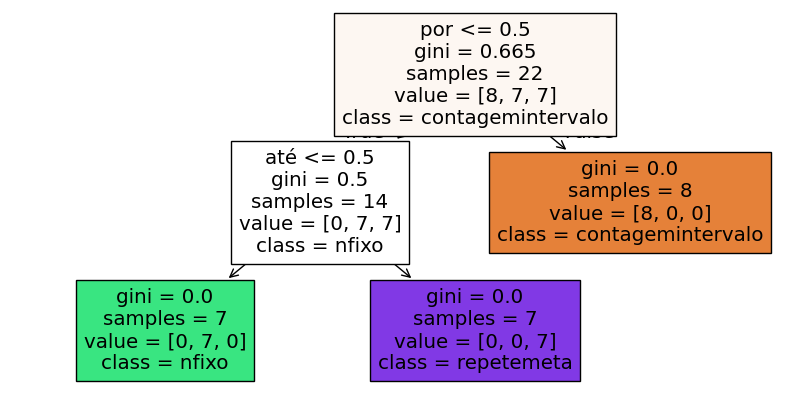

In [ ]:
X = dados["frase"]  # atributo: apenas o texto
y = dados["tipo"]   # rótulo: fica fora das entradas

# stratify mantém a mesma proporção de classes no treino e no teste
Xtreino, Xteste, ytreino, yteste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Treino:", len(Xtreino), "| Teste:", len(Xteste))

# O pipeline aplica o CountVectorizer e depois a árvore, na mesma chamada
# max_depth=3 limita o tamanho da árvore para evitar decorar o treino
modelo = make_pipeline(
    CountVectorizer(),
    DecisionTreeClassifier(max_depth=3, random_state=42),
)
modelo.fit(Xtreino, ytreino)

previsoes = modelo.predict(Xteste)
print(f"Acurácia no teste: {accuracy_score(yteste, previsoes):.1%}")

classes = ["contagemintervalo", "repetemeta", "nfixo"]
matriz = confusion_matrix(yteste, previsoes, labels=classes)
print(pd.DataFrame(matriz, index=classes, columns=classes))
ConfusionMatrixDisplay(matriz, display_labels=classes).plot(
    cmap="Blues", colorbar=False, xticks_rotation=20
)
plt.title("Teste: classes reais x previstas")
plt.show()

# Acessa as duas etapas do pipeline para inspecionar o que foi aprendido
vetor = modelo.named_steps["countvectorizer"]
arvore = modelo.named_steps["decisiontreeclassifier"]
palavras = list(vetor.get_feature_names_out())
print("Condições aprendidas (palavras usadas pela árvore):")
print(export_text(arvore, feature_names=palavras))
plt.figure(figsize=(10, 5))
plot_tree(arvore, feature_names=palavras,
          class_names=list(arvore.classes_), filled=True)
plt.show()

**Leitura:** o modelo aprende palavras que servem de pista, como "por" e "até". Essas condições têm origem nos dados, enquanto as regras R1 a R6 são escritas pelo especialista. No teste, o erro ocorre em frases de contagem sem a palavra "por", como "a cada hora". Com 8 exemplos no teste e frases de uma só autoria, nem uma acurácia alta demonstraria eficácia real.

## Motor de inferência e integração

A previsão do modelo vira o fato tipo, usado pelas regras junto com os fatos informados na consulta.

In [ ]:
# None significa que a regra não depende daquele fato
regras = [
    {"id": "R1", "tipo": "contagemintervalo", "semreposicao": None,  "n1": None,  "r1": None,  "dist": "Poisson"},
    {"id": "R2", "tipo": "repetemeta",        "semreposicao": None,  "n1": None,  "r1": True,  "dist": "Geométrica"},
    {"id": "R3", "tipo": "repetemeta",        "semreposicao": None,  "n1": None,  "r1": False, "dist": "Pascal"},
    {"id": "R4", "tipo": "nfixo",             "semreposicao": True,  "n1": None,  "r1": None,  "dist": "Hipergeométrica"},
    {"id": "R5", "tipo": "nfixo",             "semreposicao": False, "n1": True,  "r1": None,  "dist": "Bernoulli"},
    {"id": "R6", "tipo": "nfixo",             "semreposicao": False, "n1": False, "r1": None,  "dist": "Binomial"},
]

def aplicarregras(tipo, semreposicao, n1, r1):
    fatos = {"semreposicao": semreposicao, "n1": n1, "r1": r1}
    for regra in regras:
        if regra["tipo"] != tipo:
            continue
        # A regra casa se, para cada fato, ela ignora (None) ou exige o mesmo valor
        if all(regra[k] is None or regra[k] == v for k, v in fatos.items()):
            usados = {k: v for k, v in fatos.items() if regra[k] is not None}
            return {
                "tipoprevisto": tipo,
                "regra": regra["id"],
                "recomendacao": regra["dist"],
                "explicacao": f"tipo previsto = {tipo}; fatos usados = {usados or 'nenhum'}.",
            }
    raise ValueError("Nenhuma regra compatível com os fatos.")

def recomendar(frase, semreposicao=False, n1=False, r1=False):
    if not isinstance(frase, str) or not frase.strip():
        raise ValueError("A frase deve ser um texto não vazio.")
    for nome, valor in [("semreposicao", semreposicao), ("n1", n1), ("r1", r1)]:
        if not isinstance(valor, bool):
            raise ValueError(f"{nome} deve ser True ou False.")

    tipo = modelo.predict([frase])[0]
    resultado = aplicarregras(tipo, semreposicao, n1, r1)

    # Se nenhuma palavra da frase existe no vocabulário do treino, a previsão é um palpite
    conhecidas = [p for p in vetor.build_analyzer()(frase) if p in vetor.vocabulary_]
    resultado["aviso"] = (
        "Nenhuma palavra da frase existe no vocabulário do treino: previsão pouco confiável."
        if not conhecidas else "Exemplo didático; recomendação sujeita a revisão humana."
    )
    return resultado

## Três casos novos

As frases têm redação diferente da usada no treino.

In [ ]:
casos = [
    ("Acidentes por semana em um cruzamento", {}),
    ("Quantas partidas jogar até vencer a segunda", {"r1": False}),
    ("Retirar 4 bolas de uma urna sem devolvê-las", {"semreposicao": True}),
]
for i, (frase, fatos) in enumerate(casos, 1):
    print(f"\nCASO {i}: {frase!r} | fatos: {fatos or 'padrão (todos False)'}")
    for campo, valor in recomendar(frase, **fatos).items():
        print(f"{campo}: {valor}")


CASO 1: 'Acidentes por semana em um cruzamento' | fatos: padrão (todos False)
tipoprevisto: contagemintervalo
regra: R1
recomendacao: Poisson
explicacao: tipo previsto = contagemintervalo; fatos usados = nenhum.
aviso: Exemplo didático; recomendação sujeita a revisão humana.

CASO 2: 'Quantas partidas jogar até vencer a segunda' | fatos: {'r1': False}
tipoprevisto: repetemeta
regra: R3
recomendacao: Pascal
explicacao: tipo previsto = repetemeta; fatos usados = {'r1': False}.
aviso: Exemplo didático; recomendação sujeita a revisão humana.

CASO 3: 'Retirar 4 bolas de uma urna sem devolvê-las' | fatos: {'semreposicao': True}
tipoprevisto: nfixo
regra: R4
recomendacao: Hipergeométrica
explicacao: tipo previsto = nfixo; fatos usados = {'semreposicao': True}.
aviso: Exemplo didático; recomendação sujeita a revisão humana.


## O que acontece ao mudar apenas um fato

Com a mesma frase, mudando só o fato r1, o modelo não muda, mas a regra aplicada sim.

In [ ]:
frase = "Quantas partidas jogar até vencer a segunda"
for valor in (False, True):
    res = recomendar(frase, r1=valor)
    print(f"r1={valor}: {res['regra']} -> {res['recomendacao']}")

r1=False: R3 -> Pascal
r1=True: R2 -> Geométrica


## Um caso em que o modelo erra

A frase abaixo é de Poisson, pois conta chamadas em um intervalo, mas não usa a palavra "por". O modelo a classifica como nfixo e as regras entregam Binomial, com a mesma aparência de confiança de um acerto.

In [ ]:
frasedificil = "Número de chamadas recebidas pelo suporte na madrugada"
print(recomendar(frasedificil))

{'tipoprevisto': 'nfixo', 'regra': 'R6', 'recomendacao': 'Binomial', 'explicacao': "tipo previsto = nfixo; fatos usados = {'semreposicao': False, 'n1': False}.", 'aviso': 'Exemplo didático; recomendação sujeita a revisão humana.'}


## Discussão: erros, limitações e representatividade

- **Qual parte aprende com os dados:** o classificador, que vai do texto ao tipo.
- **Qual parte aplica regras humanas:** o motor R1 a R6, que vai do tipo e dos fatos à distribuição.
- **Por que semreposicao, n1 e r1 não estão no modelo:** são fatos informados na consulta. Se o rótulo fosse uma função exata deles, o modelo apenas reaprenderia as regras.
- **O que acontece ao mudar apenas um fato:** o modelo permanece igual e muda a regra aplicada.
- **Erros:** o modelo aprende palavras, não significado. Vocabulário novo pode ser classificado errado e, se o tipo vier errado, as regras propagam o erro com aparente confiança.
- **Representatividade:** 30 frases simuladas, escritas por uma só autoria, não representam como pessoas reais descrevem problemas.
- **Premissas não verificadas:** Geométrica, Pascal e Binomial exigem tentativas independentes com p constante e dois resultados, e Poisson exige taxa constante e eventos independentes. O sistema não checa isso, e essa é uma limitação declarada.
- **100% em poucos casos basta para uso real:** não, porque o teste é minúsculo e as classes são separáveis por palavras-pista.